# Week 3 - ML model pipeline walk-through

*Does Wealth Burn Carbon? Predicting absolute decoupling of CO2 per person from GDP per person, three years ahead.*

This notebook walks through the executable pipeline in `src/`. It builds the label and features, shows the leakage-safe split, fits one pipeline on one training fold, and displays the saved results of the cross-validation and of the **single** test run. It deliberately does **not** re-evaluate the test years: the test set is evaluated once, by `src/evaluate_test.py` (see `results/test_run_lock.json`); here the test results are only read from the saved files.

## 1. Setup

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import features as F, models as M, metrics as MT
pd.set_option('display.width', 200, 'display.max_columns', 30)
RES = ROOT / 'results'
print('project root:', ROOT.name)

project root: Task 3


## 2. The label on a hand-made example

The label is 1 only if CO2 per person falls **and** GDP per person rises between t and t+3 (strict inequalities).

In [2]:
toy = pd.DataFrame([
    {'iso3': c, 'year': y, 'co2_pc': co2, 'gdp_pc': gdp, 'population': 5e6}
    for c, series in {'AAA': [(1990, 10, 1000), (1993, 8, 1200)],   # CO2 down, GDP up -> 1
                      'BBB': [(1990, 10, 1000), (1993, 12, 1200)],  # CO2 up            -> 0
                      'CCC': [(1990, 10, 1000), (1993, 8, 900)]}.items()   # GDP down    -> 0
    for (y, co2, gdp) in series])
grid = F.to_grid(toy.assign(wb_name='x', region='x', income_group='x'), 1990, 1993)
F.make_label(grid, 3).query('year == 1990')[['iso3', 'year', 'co2_t', 'co2_th', 'gdp_t', 'gdp_th', 'y']]

,iso3,year,co2_t,co2_th,gdp_t,gdp_th,y
0,AAA,1990,10.0,8.0,1000.0,1200.0,1
4,BBB,1990,10.0,12.0,1000.0,1200.0,0
8,CCC,1990,10.0,8.0,1000.0,900.0,0


## 3. Modelling table: eligible rows, pool and base rate

Only the pool (window start years 1993-2013) is used for exploration and model selection.

In [3]:
D = F.build_dataset()
pool = F.get_pool(D)
print(f'eligible rows: {len(D):,}   pool rows: {len(pool):,}   pool countries: {pool.iso3.nunique()}   pool base rate: {pool.y.mean():.3f}')
pool[['iso3', 'year', 'y'] + F.FEATURES[:6]].head()

eligible rows: 5,283   pool rows: 4,093   pool countries: 201   pool base rate: 0.268


,iso3,year,y,ln_gdp_pc,gdp_g1,gdp_cagr3,gdp_vol5,ln_pop,pop_g3
0,ABW,1993,0,10.160845,0.004910,0.014571,0.039190,11.207555,0.053531
1,AGO,1993,0,7.468926,-0.306175,-0.140933,0.115754,16.367073,0.032763
2,ALB,1993,1,7.134635,0.097398,-0.097876,0.168003,14.987152,-0.006065
3,AND,1993,0,10.185588,-0.060139,-0.053587,0.036594,11.055198,0.061595
4,ARE,1993,1,11.001149,-0.036990,-0.034510,0.067363,14.613960,0.052511


In [4]:
pd.read_csv(RES / 'sample_flow.csv')

,stage,n_remaining,n_dropped
0,"all entity-years, t = 1993-2019",6183,0
1,no CO2 per capita > 0 at t,5765,418
2,no GDP per capita > 0 at t,5294,471
3,no CO2 per capita > 0 at t+3,5294,0
4,no GDP per capita > 0 at t+3,5283,11


## 4. Leakage-safe folds

Rolling-origin folds with a 3-year purge gap: every training label window (t .. t+3) ends before the validation block starts.

In [5]:
folds = F.rolling_origin_folds(pool)
for k, (tr, va) in enumerate(folds, 1):
    ytr, yva = pool.year.to_numpy()[tr], pool.year.to_numpy()[va]
    assert ytr.max() + 3 < yva.min()
    print(f'fold {k}: train t <= {ytr.max()} ({len(tr):,} rows) | purge {ytr.max()+1}-{yva.min()-1} | validate {yva.min()}-{yva.max()} ({len(va):,} rows)')

fold 1: train t <= 1995 (569 rows) | purge 1996-1998 | validate 1999-2001 (583 rows)
fold 2: train t <= 1998 (1,145 rows) | purge 1999-2001 | validate 2002-2004 (585 rows)
fold 3: train t <= 2001 (1,728 rows) | purge 2002-2004 | validate 2005-2007 (586 rows)
fold 4: train t <= 2004 (2,313 rows) | purge 2005-2007 | validate 2008-2010 (597 rows)
fold 5: train t <= 2007 (2,899 rows) | purge 2008-2010 | validate 2011-2013 (597 rows)


## 5. One pipeline, fitted on one training fold only

Correlation filter -> winsorise -> impute (median + indicators) -> standardise -> elastic-net logistic regression. All of these learn from the training fold only.

In [6]:
cfg = json.loads((RES / 'frozen_config.json').read_text())
lr_cfg = cfg['models']['lr']
print(lr_cfg)
pipe = M.make_pipeline('lr', lr_cfg['imputer'], lr_cfg['class_weight'], lr_cfg['params'])
print([name for name, _ in pipe.steps])
tr, va = folds[2]
X, y = pool[F.FEATURES], pool['y'].to_numpy()
pipe.fit(X.iloc[tr], y[tr])
p = pipe.predict_proba(X.iloc[va])[:, 1]
print('filter dropped:', [F.FEATURES[j] for j in pipe.named_steps['corr_filter'].dropped_])
print(f'fold 3 PR-AUC = {MT.safe_ap(y[va], p):.3f}  (fold base rate {y[va].mean():.3f});  ROC-AUC = {MT.safe_auc(y[va], p):.3f}')

{'imputer': 'median', 'class_weight': None, 'params': {'l1_ratio': 0.7, 'C': 3}, 'threshold': 0.12391763306856672}
['corr_filter', 'winsorise', 'impute', 'scale', 'clf']


filter dropped: ['ln_energy_pc']
fold 3 PR-AUC = 0.309  (fold base rate 0.247);  ROC-AUC = 0.570


## 6. Cross-validation results (saved by `src/evaluate_cv.py`)

In [7]:
display(pd.read_csv(RES / 'stage1_selection.csv').round(3))
display(pd.read_csv(RES / 'cv_model_comparison.csv')[['model', 'imputer', 'class_weight', 'pr_auc_mean', 'pr_auc_se', 'roc_auc_mean', 'brier_mean', 'ece_mean']].round(3))
display(pd.read_csv(RES / 'model_selection.csv').T)

,model,best_imputer,best_class_weight,best_pr_auc,best_se,n_within_one_se,chosen_imputer,chosen_class_weight,chosen_pr_auc
0,lr,iterative,none,0.350,0.035,6,median,none,0.345
1,rf,median,balanced,0.386,0.044,6,median,none,0.384
2,hgb,median,none,0.376,0.037,8,native,none,0.363


,model,imputer,class_weight,pr_auc_mean,pr_auc_se,roc_auc_mean,brier_mean,ece_mean
0,lr,median,none,0.346,0.035,0.597,0.200,0.075
1,rf,median,none,0.384,0.051,0.624,0.193,0.059
2,hgb,native,none,0.380,0.038,0.626,0.197,0.083
3,prior,NaN,NaN,0.276,0.020,0.500,0.200,0.032
4,persistence,NaN,NaN,0.290,0.023,0.528,0.369,0.369


,0
best_model,rf
best_pr_auc,0.384452
best_se,0.050889
threshold_for_simpler,0.333563
models_within_one_se,"lr,rf,hgb"
chosen_model,lr
chosen_pr_auc,0.346472
rule,highest mean PR-AUC; simpler model within 1 SE...


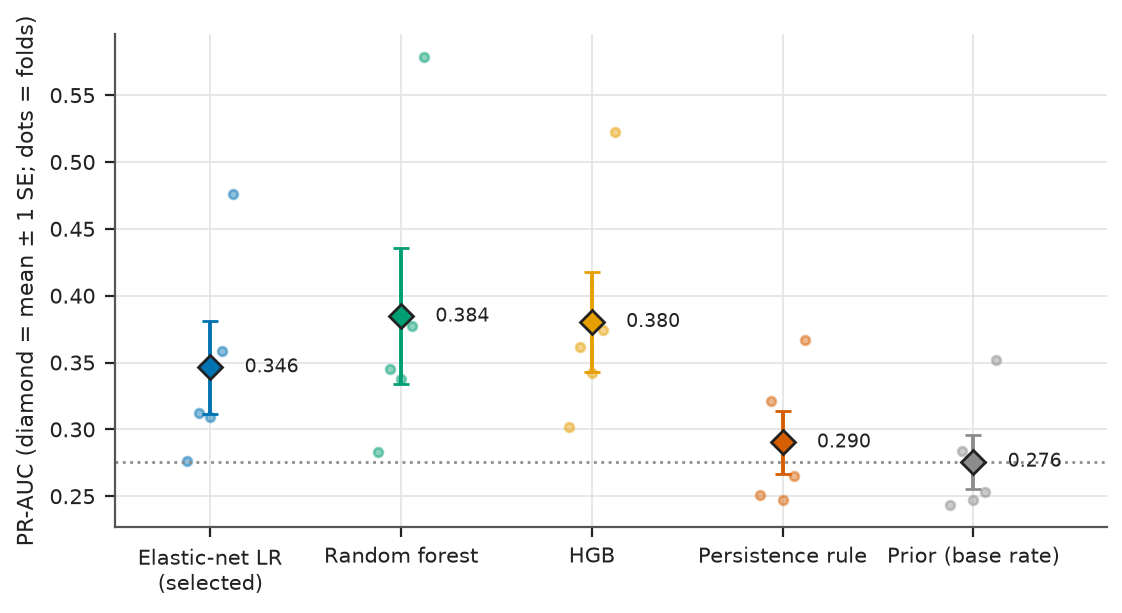

In [8]:
display(Image(ROOT / 'figures' / 'fig_cv_model_comparison.png'))

## 7. Frozen configuration

Written before the test run: chosen model, preprocessing, hyper-parameters, and the F1-maximising threshold from pooled out-of-fold predictions.

In [9]:
print(json.dumps({k: cfg[k] for k in ['frozen_utc', 'chosen_model', 'baseline_model', 'threshold_rule']}, indent=2))
pd.DataFrame(cfg['models']).T[['imputer', 'class_weight', 'threshold']]

{
  "frozen_utc": "2026-11-05 12:33:54",
  "chosen_model": "lr",
  "baseline_model": "lr",
  "threshold_rule": "maximise F1 on pooled out-of-fold rolling-origin predictions of the pool"
}


,imputer,class_weight,threshold
lr,median,None,0.123918
rf,median,None,0.19744
hgb,native,None,0.172852


## 8. The single test run (read from saved files)

In [10]:
lock = json.loads((RES / 'test_run_lock.json').read_text())
print(lock['run_utc'], '-', lock['note'])
tm = pd.read_csv(RES / 'test_metrics.csv')
tm[['model', 'threshold', 'pr_auc', 'pr_auc_lo', 'pr_auc_hi', 'roc_auc', 'f1', 'mcc']].round(3)

2026-11-05 12:47:59 - The test set was evaluated once. Re-running is blocked by the existence of this file.


,model,threshold,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,f1,mcc
0,lr,0.124,0.390,0.310,0.495,0.688,0.405,0.072
1,rf,0.197,0.471,0.372,0.575,0.700,0.436,0.172
2,hgb,0.173,0.467,0.368,0.564,0.696,0.451,0.213
3,persistence,0.500,0.284,0.228,0.340,0.568,0.362,0.130
4,prior,0.500,0.249,0.205,0.295,0.500,0.000,0.000


In [11]:
display(pd.read_csv(RES / 'test_paired_differences.csv').drop_duplicates().round(3))
display(pd.read_csv(RES / 'test_posthoc.csv').round(3))

,model_a,model_b,metric,diff,ci_low,ci_high,share_boot_diff_le_0
0,lr,persistence,pr_auc,0.106,0.051,0.192,0.000
1,lr,persistence,roc_auc,0.120,0.056,0.183,0.000
2,lr,prior,pr_auc,0.141,0.084,0.231,0.000
3,lr,prior,roc_auc,0.188,0.123,0.251,0.000
6,hgb,rf,pr_auc,-0.004,-0.051,0.039,0.622
7,hgb,rf,roc_auc,-0.004,-0.032,0.024,0.604


,model_a,model_b,metric,value_a,value_b,diff,ci_low,ci_high,share_boot_diff_le_0
0,lr,rf,pr_auc,0.390,0.471,-0.081,-0.138,-0.024,0.996
1,lr,rf,roc_auc,0.688,0.700,-0.012,-0.044,0.025,0.757
2,lr,hgb,pr_auc,0.390,0.467,-0.077,-0.131,-0.011,0.988
3,lr,hgb,roc_auc,0.688,0.696,-0.008,-0.054,0.042,0.632
4,lr,group_prior,pr_auc,0.390,0.379,0.011,-0.048,0.089,0.331
5,lr,group_prior,roc_auc,0.688,0.689,-0.000,-0.062,0.059,0.500
6,rf,group_prior,pr_auc,0.471,0.379,0.092,0.018,0.172,0.008
7,rf,group_prior,roc_auc,0.700,0.689,0.011,-0.051,0.068,0.364
8,persistence,group_prior,pr_auc,0.284,0.379,-0.095,-0.153,-0.042,1.000
9,persistence,group_prior,roc_auc,0.568,0.689,-0.121,-0.186,-0.058,1.000


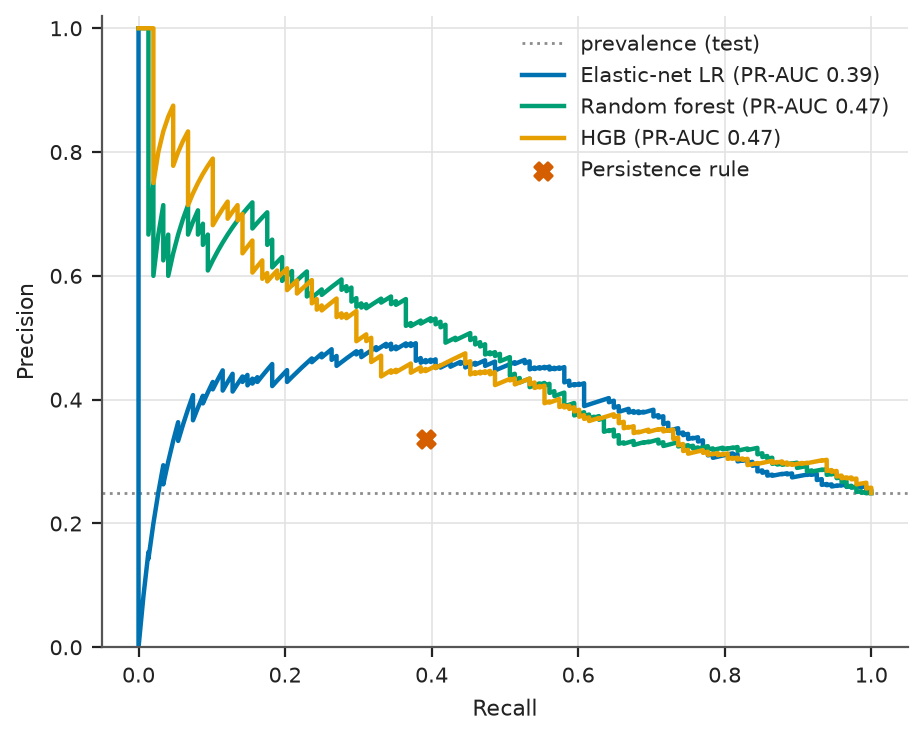

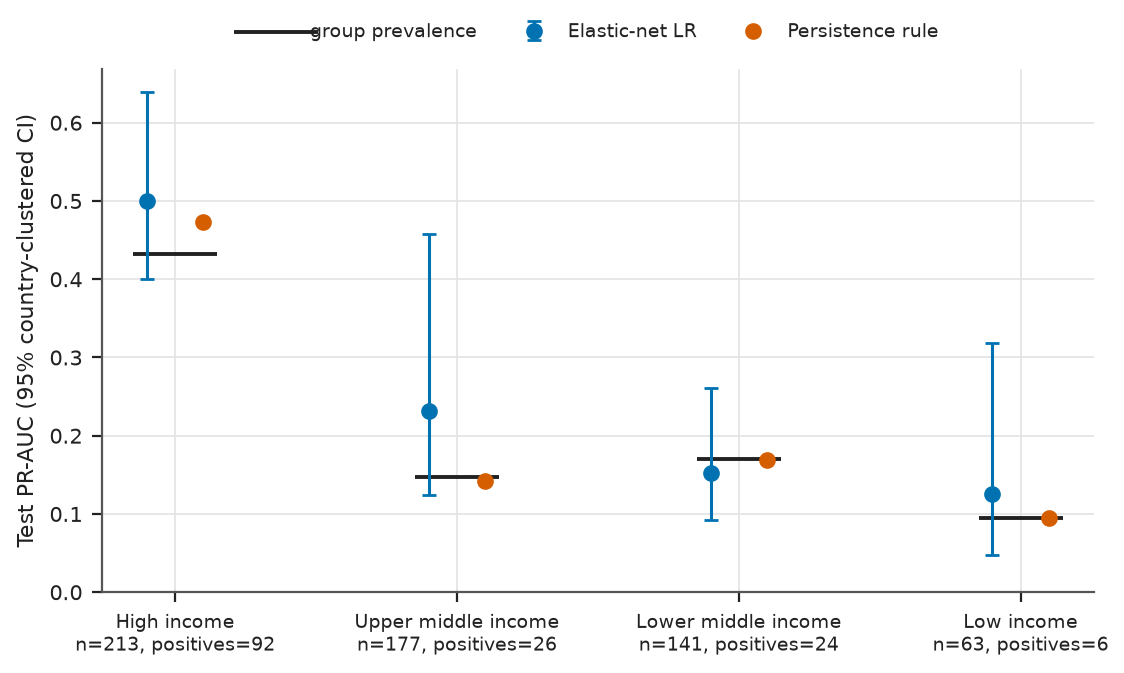

In [12]:
for f in ['fig_test_precision_recall', 'fig_subgroup_income']:
    display(Image(ROOT / 'figures' / f'{f}.png'))

## 9. Integrity tests

In [13]:
import subprocess
r = subprocess.run([sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider'], cwd=ROOT, capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1])

1 failed, 30 passed in 3.87s
